# Probe: why does the first token of an assistant turn come out garbled?

Interactive version of `probe_first_token.py` -- edit the config cell below and re-run cells 3 onward to try a different (adapter / dtype / audio) combination without reloading the whole notebook. Uses the shared helpers in `probe_lib.py` (same logic `run_all.sh` uses for the scripted three-way comparison), so results here are directly comparable to `out/*.json`.

Background: the fine-tuned model's first generated token should be `<tool_call>` (id 151657) but sometimes comes out as id 124 (a lone byte-fallback token that can't decode to valid UTF-8 alone, i.e. shows up as `�`). Training data + training-time tokenization were already verified clean (see the chat history / module docstring in `probe_lib.py`) -- this notebook isolates whether audio input, the LoRA adapter, or bf16 precision is the actual driver.

Must run under the `ms-swift` conda env kernel.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import torch
import probe_lib
from probe_lib import DEFAULT_ADAPTER, DEFAULT_MODEL, DEFAULT_SAMPLE_ID, DTYPE_MAP

## Config -- edit this cell, then re-run everything below

Toggle one variable at a time (that's the point of the isolation test): `USE_ADAPTER`, `DTYPE`, `USE_AUDIO`.

In [2]:
USE_ADAPTER = True   # False = raw base checkpoint, no LoRA
ADAPTER_PATH = "/home/u1501463/tool_use_LALM/tool_use_training/stage1_training/v2-20260807-195833/checkpoint-200"   # set to a checkpoint dir to override DEFAULT_ADAPTER; ignored if USE_ADAPTER=False
DTYPE = "fp32"        # "bf16" | "fp16" | "fp32"
USE_AUDIO = True      # False = strip <audio_N><audio> tags, text-only prompt
SAMPLE_ID = "bench_bd77f13f1024"
TOPK = 20

adapter_dir = (ADAPTER_PATH or DEFAULT_ADAPTER) if USE_ADAPTER else None
print(f"adapter={adapter_dir!r}\ndtype={DTYPE}\nuse_audio={USE_AUDIO}\nsample_id={SAMPLE_ID}")

adapter='/home/u1501463/tool_use_LALM/tool_use_training/stage1_training/v2-20260807-195833/checkpoint-200'
dtype=fp32
use_audio=True
sample_id=bench_bd77f13f1024


## Load model + build the prompt

This is the slow cell (~1-2 min: full 7B bf16/fp32 weight load). If you change `USE_ADAPTER`/`DTYPE` above, re-run from here -- `USE_AUDIO`-only changes only need the "build messages" cell re-run (see below).

In [3]:
# If a previous engine is still around (e.g. you changed DTYPE/USE_ADAPTER and
# re-ran this cell), free its GPU memory first.
try:
    del engine
    torch.cuda.empty_cache()
except NameError:
    pass

engine = probe_lib.load_engine(DEFAULT_MODEL, adapter_dir, DTYPE_MAP[DTYPE], max_new_tokens=1024)
captured = probe_lib.patch_generate_to_capture_scores(engine.engine.model)

/home/u1501463/miniconda3/envs/ms-swift/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Model config: tts_text_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151860. This may result in unexpected behavior.
[transformers] Model config: tts_text_end_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151861. This may result in unexpected behavior.
[transformers] Model config: tts_text_pad_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151859. This may result in unexpected behavior.
[transformers] Model config: vision_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151652. This may result in unexpected behavior.
[transformers] Model

In [4]:
sample = probe_lib.load_sample(SAMPLE_ID, results_json='/home/u1501463/tool_use_LALM/testing_tool_use_benchmark/results.json')
messages, audios = probe_lib.build_messages(sample["entry"], sample["system_prompt"], USE_AUDIO)
print("user message (head):", repr(messages[1]["content"])[:200])
print("audios:", audios)

user message (head): 'Transform the source audio into the target audio using the available tools.\n\nSource audio: <audio_0><audio>\nTarget audio: <audio_1><audio>'
audios: ['/work/u1501463/tool_use_benchmark_audio/bench_bd77f13f1024/A_sample-000014441.wav', '/work/u1501463/tool_use_benchmark_audio/bench_bd77f13f1024/B.wav']


## Generate + inspect the first token's logits

In [5]:
request = engine._InferRequest(messages=messages, audios=audios)
response = engine.engine.infer([request], engine.request_config)[0]
content = response.choices[0].message.content
token_ids = list(response.choices[0].token_ids or [])

print("content:", repr(content))
print("first 10 token ids:", token_ids[:10])
print("contains U+FFFD:", "�" in content)

content: 'The target audio is a shorter segment of the current audio, running only from 00:00:00.000 to 00:00:05.367. I should clip the current audio to that window.\n<tool_call>\n{"name": "clipping", "arguments": {"audio_begin": "00:00:00.000", "audio_end": "00:00:05.367", "audio_id": "audio_0"}}\nบุรี'
first 10 token ids: [785, 2169, 7699, 374, 264, 23327, 10238, 315, 279, 1482]
contains U+FFFD: False


In [6]:
tokenizer = engine.engine.tokenizer
ids = token_ids[:-1]

tokens = tokenizer.convert_ids_to_tokens(ids)
decoded = tokenizer.decode(ids, clean_up_tokenization_spaces=False)

print("ids:", ids)
print("tokens:", tokens)
print("decoded:", repr(decoded))

ids: [785, 2169, 7699, 374, 264, 23327, 10238, 315, 279, 1482, 7699, 11, 4303, 1172, 504, 220, 15, 15, 25, 15, 15, 25, 15, 15, 13, 15, 15, 15, 311, 220, 15, 15, 25, 15, 15, 25, 15, 20, 13, 18, 21, 22, 13, 358, 1265, 12327, 279, 1482, 7699, 311, 429, 3241, 624, 151657, 198, 4913, 606, 788, 330, 564, 5654, 497, 330, 16370, 788, 5212, 16736, 23338, 788, 330, 15, 15, 25, 15, 15, 25, 15, 15, 13, 15, 15, 15, 497, 330, 16736, 6213, 788, 330, 15, 15, 25, 15, 15, 25, 15, 20, 13, 18, 21, 22, 497, 330, 16736, 842, 788, 330, 16736, 62, 15, 95642, 133153]
tokens: ['The', 'Ġtarget', 'Ġaudio', 'Ġis', 'Ġa', 'Ġshorter', 'Ġsegment', 'Ġof', 'Ġthe', 'Ġcurrent', 'Ġaudio', ',', 'Ġrunning', 'Ġonly', 'Ġfrom', 'Ġ', '0', '0', ':', '0', '0', ':', '0', '0', '.', '0', '0', '0', 'Ġto', 'Ġ', '0', '0', ':', '0', '0', ':', '0', '5', '.', '3', '6', '7', '.', 'ĠI', 'Ġshould', 'Ġclip', 'Ġthe', 'Ġcurrent', 'Ġaudio', 'Ġto', 'Ġthat', 'Ġwindow', '.Ċ', '<tool_call>', 'Ċ', '{"', 'name', '":', 'Ġ"', 'cl', 'ipping', '",', 'Ġ"', 

In [7]:
out = captured.get("out")
assert out is not None and getattr(out, "scores", None), "no scores captured -- did generate() actually get called?"

def print_top_tokens_at_position(position=0, n=10, batch=0):
    logits = out.scores[position][batch].float()
    values, indices = torch.topk(logits, n)
    print(f"position={position} batch={batch} top-{n}")
    for rank, (val, idx) in enumerate(zip(values.tolist(), indices.tolist()), start=1):
        token = tokenizer.convert_ids_to_tokens(idx)
        print(f"{rank:>2}: id={idx} logit={val:.4f} token={token!r}")
position=110
print_top_tokens_at_position(position=position, n=100)


position=110 batch=0 top-100
 1: id=133153 logit=13.8472 token='à¸ļà¸¸à¸£à¸µ'
 2: id=132731 logit=13.8472 token='à¹Ĥà¸£à¸ĩà¹Ģà¸£à¸µà¸¢à¸Ļ'
 3: id=125816 logit=13.8471 token='à¹Ģà¸Ĺà¹Īà¸²'
 4: id=138381 logit=13.8471 token='à¹Ģà¸ļà¸·à¹īà¸Ńà¸ĩ'
 5: id=124254 logit=13.8470 token='à¸ģà¸±à¸Ļ'
 6: id=136680 logit=13.8470 token='à¸ģà¹īà¸²à¸§'
 7: id=151149 logit=13.8470 token='ï§Ł'
 8: id=135449 logit=13.8470 token='à¸£à¸²à¸¢à¹Ħà¸Ķà¹ī'
 9: id=139837 logit=13.8469 token='à¸Ļà¸±à¸ģà¹Ģà¸ķ'
10: id=129140 logit=13.8469 token='à¸£à¸¸à¹Īà¸Ļ'
11: id=140059 logit=13.8469 token='à¸ģà¸£à¸¸à¸ĩà¹Ģà¸Ĺà¸ŀà¸¯'
12: id=123948 logit=13.8469 token='à¸ķà¸´'
13: id=143546 logit=13.8469 token='à¸Ĥà¸Ļà¸ªà¹Īà¸ĩ'
14: id=138134 logit=13.8469 token='à¹Ģà¸Ĭà¸´à¸į'
15: id=125736 logit=13.8469 token='à¸Ľà¸±à¸įà¸«à¸²'
16: id=141065 logit=13.8468 token='à¸Īà¸°à¹Ħà¸Ķà¹īà¸£à¸±à¸ļ'
17: id=143441 logit=13.8468 token='à¸ļà¸£à¸£à¸Īà¸¸'
18: id=127263 logit=13.8468 token='à¸Ĥà¸±à¸ļ'
19: id=142536 logit=13.8468 token='Ġà¸¡à¸µà¸Ļà¸²'


In [ ]:
import torch

import torch.nn.functional as F

token_text = "<tool_call>"
token_id = tokenizer.convert_tokens_to_ids([token_text])[0]

# stack scores into [seq_len, batch, vocab]
logits = torch.stack([score[0] for score in out.scores], dim=0)
probs = F.softmax(logits.float(), dim=-1)

token_probs = probs[:, token_id].cpu().numpy()

print(f"token={token_text!r} id={token_id}")
for position, prob in enumerate(token_probs):
    print(f"position={position:3d} prob={prob:.6f}")

token='</tool_call>' id=151658
position=  0 prob=0.000000
position=  1 prob=0.000000
position=  2 prob=0.000000
position=  3 prob=0.000000
position=  4 prob=0.000000
position=  5 prob=0.000000
position=  6 prob=0.000000
position=  7 prob=0.000000
position=  8 prob=0.000000
position=  9 prob=0.000000
position= 10 prob=0.000000
position= 11 prob=0.000000
position= 12 prob=0.000000
position= 13 prob=0.000000
position= 14 prob=0.000000
position= 15 prob=0.000000
position= 16 prob=0.000000
position= 17 prob=0.000000
position= 18 prob=0.000000
position= 19 prob=0.000000
position= 20 prob=0.000000
position= 21 prob=0.000000
position= 22 prob=0.000000
position= 23 prob=0.000000
position= 24 prob=0.000000
position= 25 prob=0.000000
position= 26 prob=0.000000
position= 27 prob=0.000000
position= 28 prob=0.000000
position= 29 prob=0.000000
position= 30 prob=0.000000
position= 31 prob=0.000000
position= 32 prob=0.000000
position= 33 prob=0.000000
position= 34 prob=0.000000
position= 35 prob=0.0000

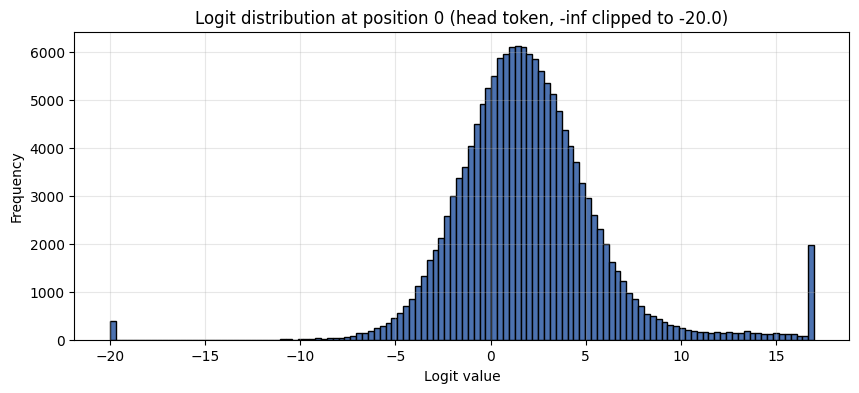

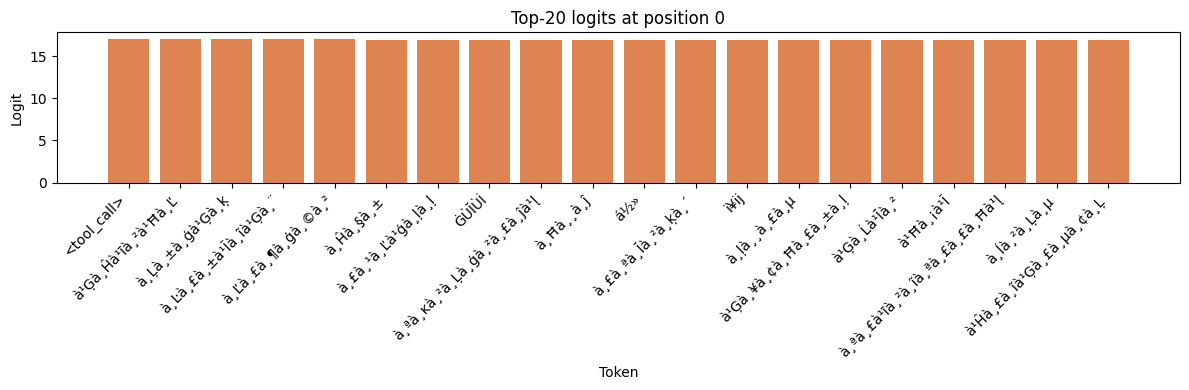

In [8]:
import matplotlib.pyplot as plt
import numpy as np

position = 0
batch = 0

logits = out.scores[position][batch].float().cpu().numpy()

lower_bound = -20.0  # clip -inf (masked-out tokens) to this floor before plotting
logits_clipped = np.clip(logits, lower_bound, None)

plt.figure(figsize=(10, 4))
plt.hist(logits_clipped, bins=120, color="#4C72B0", edgecolor="black")
plt.title(f"Logit distribution at position {position} (head token, -inf clipped to {lower_bound})")
plt.xlabel("Logit value")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()

topk = 20
values, indices = torch.topk(out.scores[position][batch].float(), topk)
tokens = tokenizer.convert_ids_to_tokens(indices.tolist())

plt.figure(figsize=(12, 4))
plt.bar(range(topk), values.cpu().numpy(), color="#DD8452")
plt.xticks(range(topk), tokens, rotation=45, ha="right")
plt.title(f"Top-{topk} logits at position {position}")
plt.xlabel("Token")
plt.ylabel("Logit")
plt.tight_layout()
plt.show()

In [ ]:
token_text = "<tool_call>"  # or "</tool_call>"
token_id = tokenizer.convert_tokens_to_ids([token_text])[0]
first_logits = out.scores[0][0].float()

print(f"token={token_text!r} id={token_id}")
print(f"logit={first_logits[token_id].item():.4f}")

In [ ]:
out = captured.get("out")
assert out is not None and getattr(out, "scores", None), "no scores captured -- did generate() actually get called?"

first_logits = out.scores[0][0].float()  # step 0 (first generated token), batch 0
tokenizer = engine.engine.tokenizer
values, indices = torch.topk(first_logits, TOPK)

tool_call_logit = first_logits[probe_lib.TOOL_CALL_TOKEN_ID].item()
tool_call_rank = int((first_logits > tool_call_logit).sum().item())

print(f"<tool_call> (id={probe_lib.TOOL_CALL_TOKEN_ID}) logit={tool_call_logit:.4f} rank={tool_call_rank}")
print(f"top-{TOPK} logit spread: {(values[0] - values[-1]).item():.4f}\n")
print(f"{'rank':>4} {'id':>8} {'logit':>10}  piece")
for rank, (val, idx) in enumerate(zip(values.tolist(), indices.tolist())):
    marker = "  <-- <tool_call>" if idx == probe_lib.TOOL_CALL_TOKEN_ID else ""
    print(f"{rank:>4} {idx:>8} {val:>10.4f}  {tokenizer.convert_ids_to_tokens(idx)!r}{marker}")

## What to look for

- **`spread` small (sub-~0.5) and many unrelated tokens in the top-k** (byte-fallback chars, `<tool_call>`, random unrelated tokens all bunched together) -> degenerate/flat distribution at this position, not a confidently-wrong prediction.
- Flip `DTYPE` to `"fp32"` and re-run: if the spread opens up and `<tool_call>` jumps to rank 0 with a clear margin, this is a bf16 precision artifact.
- Flip `USE_AUDIO` to `False` and re-run: if the flatness disappears, it's specific to audio-embedding injection (e.g. an mrope position-id issue at the audio-to-text boundary).
- Flip `USE_ADAPTER` to `False` and re-run: if the raw base checkpoint shows the *same* flatness on this prompt, the LoRA fine-tune isn't the cause -- it's the base model + inference stack.

In [ ]:
# Optional: free GPU memory before switching DTYPE/USE_ADAPTER and re-running from the "Load model" cell.
del engine
torch.cuda.empty_cache()